In [1]:
!pip install -U google-generativeai pandas Pillow

INFO: pip is looking at multiple versions of grpcio-status to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of grpcio-status to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 8.5 MB/s  0:00:00
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -------- ------------------------------- 2.1/9.7 MB 10.7 MB/s eta 0:00:01
   ------------------ --------------------- 4.5/9.7 MB 10.8 MB/s eta 0:00:01
   -------------------------- ------------- 6.6/9.7 MB 10.9 MB/s eta 0:00:01
   ------------------------------------ --- 8.9/9.7 MB 10.9 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 10.3 MB/s  0:00:00
   ---------------------------------------- 0.0/7.0 MB ? eta -:--:--
   ----------- -----------------

  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import google.generativeai as genai
from PIL import Image
import requests
from io import BytesIO
import time
import numpy as np
import os
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

C:\Users\00zso\AppData\Local\Temp\ipykernel_25892\606122626.py:2: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  import google.generativeai as genai


In [ ]:
# Directory to load and save features
save_dir = "saved_features_new"

In [ ]:
# Load train, val, and test indices
train_idx = np.load(os.path.join(save_dir, "train_idx.npy"))
val_idx   = np.load(os.path.join(save_dir, "val_idx.npy"))
test_idx  = np.load(os.path.join(save_dir, "test_idx.npy"))

NameError: name 'save_dir' is not defined

In [2]:
# load preprocessed data
df = pd.read_csv('final_dataset_preprocessed_final.csv')

KeyboardInterrupt: 

In [ ]:
# Extract test set using indices
df_test = df.iloc[test_idx]

subset_size = 1500
subset_df = df_test.sample(n=subset_size, random_state=42)

In [ ]:
# Save the subset to a new CSV file
subset_df.to_csv("llm_few_shot_subset.csv", index=False)

In [ ]:
# check the shape of the subset
print(subset_df.shape)

(1500, 51)


In [ ]:
# load the saved subset
subset_df = pd.read_csv("gemini_results_few_shot.csv")

# Quick check
print(subset_df.shape)
print(subset_df.head())

(1500, 53)
                                               blurb category_name  \
0  A collection of items based on the Earths pre-...   Digital Art   
1  An EP that explores and mixes two genres. R&B ...           R&B   
2  💞✨Poke Pins are back, and sparklier than ever! ✨💞   Accessories   
3  Battling crazy sheep, rough terrain and S4 mRC...         Photo   
4  I want to change peoples life through the phot...        People   

  category_parent_name country  creator_has_admin_message_badge  \
0                  Art      GB                            False   
1                Music      US                            False   
2              Fashion      US                            False   
3           Journalism      US                            False   
4          Photography      US                            False   

   creator_ppo_has_action  creator_backing_action_count currency  \
0                   False                           0.0      GBP   
1                   False    

In [ ]:
# Configure with API Key
genai.configure(api_key="API_KEY")
model = genai.GenerativeModel('gemini-2.5-flash')

In [4]:
# Pick one success and one failure from the subset
success_example = subset_df[subset_df['success'] == 1].sample(1, random_state=42).iloc[0]
failure_example = subset_df[subset_df['success'] == 0].sample(1, random_state=42).iloc[0]

few_shot_examples = [success_example, failure_example]

In [ ]:
# Function to format an example for the LLM
def format_example(row):
    # Download the image
    try:
        response = requests.get(row.get('photo_1536x864', None), timeout=5)
        img = Image.open(BytesIO(response.content)).convert("RGB")
    except Exception:
        img = None
    
    text = f"""
### EXAMPLE CAMPAIGN
- Campaign Name: {row['name']}
- Category: {row['category_name']}
- Country of Registration: {row['country']}
- Is Local: {row['is_local']}
- Original Currency: {row['currency']}
- Goal converted to USD: ${row['goal_converted_USD']} USD
- Campaign Duration: {row['campaign_duration_days']} days
- Prelaunch Activated: {row['prelaunch_activated']}
- Days Between Created & Launched: {row['days_between_created_launched']}
- Launch Day: {row['launched_day']}
- Launch Day of Week: {row['launched_day_of_week']}
- Launch Hour: {row['launched_hour']}
- Launch Month: {row['launched_month']}
- Number of Reward Tiers: {row['num_reward_tiers']}
- Lowest Pledge Level USD: ${row['lowest_pledge_level_usd']} USD
- Highest Pledge Level USD: ${row['highest_pledge_level_usd']} USD
- Has Reward Images: {row['has_reward_images']}
- Has Restricted Shipping: {row['has_restricted_shipping']}
- Video Available: {row['video']}
- Total Media Assets: {row['total_media_assets']}
- Number of Static Images: {row['num_static_images']}
- Number of Animated Content: {row['num_animated_content']}

- Campaign Story: {str(row['story_html_text_llm'])}
- Title Image:
- Outcome: {'Successful' if row['success'] == 1 else 'Failed'}
"""
    return text, img

In [ ]:
# Main function to get multimodal prediction from Gemini
def get_multimodal_prediction(row, few_shot_examples):
    # Download the target campaign image
    try:
        target_img = Image.open(BytesIO(requests.get(row['photo_1536x864'], timeout=5).content)).convert("RGB")
    except Exception:
        target_img = None

    # Build the content list with few-shot examples (text + images)
    content_list = []
    for ex in few_shot_examples:
        ex_text, ex_img = format_example(ex)
        content_list.append(ex_text)
        if ex_img:
            content_list.append(ex_img)

    # Build target campaign text
    target_text = f"""
### TARGET CAMPAIGN
- Campaign Name: {row['name']}
- Category: {row['category_name']}
- Country of Registration: {row['country']}
- Is Local: {row['is_local']}
- Original Currency: {row['currency']}
- Goal converted to USD: ${row['goal_converted_USD']} USD
- Campaign Duration: {row['campaign_duration_days']} days
- Prelaunch Activated: {row['prelaunch_activated']}
- Days Between Created & Launched: {row['days_between_created_launched']}
- Launch Day: {row['launched_day']}
- Launch Day of Week: {row['launched_day_of_week']}
- Launch Hour: {row['launched_hour']}
- Launch Month: {row['launched_month']}
- Number of Reward Tiers: {row['num_reward_tiers']}
- Lowest Pledge Level USD: ${row['lowest_pledge_level_usd']} USD
- Highest Pledge Level USD: ${row['highest_pledge_level_usd']} USD
- Has Reward Images: {row['has_reward_images']}
- Has Restricted Shipping: {row['has_restricted_shipping']}
- Video Available: {row['video']}
- Total Media Assets: {row['total_media_assets']}
- Number of Static Images: {row['num_static_images']}
- Number of Animated Content: {row['num_animated_content']}
- Campaign Story: {str(row['story_html_text_llm'])}
"""
    content_list.append(target_text)
    if target_img:
        content_list.append(target_img)

    # Build main instruction prompt
    instruction = """
You are a crowdfunding analyst.
For context, research emphasizes that crowdfunding success is a highly complex, multi-causal phenomenon where no single variable guarantees success or failure. Instead, it's the interplay of various factors that shapes outcomes.
Predicting the success of a Kickstarter campaign is challenging due to the multifaceted nature of these factors, which include project quality, creator reputation, marketing efforts, timing, and external market conditions. Even with access to comprehensive data, accurately forecasting outcomes remains difficult because of the dynamic and unpredictable elements involved.

You are given a few examples of Kickstarter campaigns and their outcomes (text + images) above.
Now, predict if the following Kickstarter campaign will be 'Successful' (1) or 'Failed' (0).
Provide a binary answer (1 for success, 0 for failure) followed by a 2-sentence explanation.
"""

    # Send to Gemini
    try:
        response = model.generate_content([instruction] + content_list,
                                          generation_config={"temperature": 0})
        return response.text.strip()
    except Exception as e:
        return f"Error at index {row.name}: {str(e)}"

In [ ]:
# Execution with Rate Limit Handling
print("Sending requests to Gemini...")
results = []
# Initialize the column if it doesn't exist
if 'raw_response' not in subset_df.columns:
    subset_df['raw_response'] = None
# Explicitly set to object dtype to hold long strings
subset_df['raw_response'] = subset_df['raw_response'].astype('object')

# Catch the empty rows
is_not_few_shot = ~subset_df.index.isin([ex.name for ex in few_shot_examples])
is_empty_or_error = (
    subset_df['raw_response'].isna() | 
    subset_df['raw_response'].astype(str).str.startswith("Error")
)

rows_to_predict = subset_df[is_not_few_shot & is_empty_or_error].head(20)

for i, (index, row) in enumerate(rows_to_predict.iterrows()):
    res = get_multimodal_prediction(row, few_shot_examples)
    # Save result directly to the dataframe
    subset_df.loc[index, 'raw_response'] = res
    
    print(f"Processed {i+1}/{len(rows_to_predict)} rows today")
    
    # Sleep for 10 seconds to stay under the Free Tier 15 RPM limit
    time.sleep(10) 

# Save the results back to subset_df
subset_df.to_csv("gemini_results_few_shot.csv", index=False)

Sending requests to Gemini...
Processed 1/20 rows today
Processed 2/20 rows today
Processed 3/20 rows today
Processed 4/20 rows today
Processed 5/20 rows today
Processed 6/20 rows today
Processed 7/20 rows today
Processed 8/20 rows today
Processed 9/20 rows today
Processed 10/20 rows today
Processed 11/20 rows today
Processed 12/20 rows today
Processed 13/20 rows today
Processed 14/20 rows today
Processed 15/20 rows today
Processed 16/20 rows today
Processed 17/20 rows today
Processed 18/20 rows today
Processed 19/20 rows today
Processed 20/20 rows today


In [8]:
# number of rows with llm predictions
prediction_count = subset_df['raw_response'].notna().sum()
print(f"Number of rows with LLM predictions: {prediction_count}")

# number of valid predictions (not empty and not error)
valid_count = subset_df['raw_response'].apply(lambda x: isinstance(x, str) and not x.startswith("Error") and x.strip() != '').sum()
print(f"Number of rows with valid predictions: {valid_count}")

# number of rows with errors in raw_response
error_count = subset_df['raw_response'].str.contains("Error", na=False).sum()
print(f"Number of rows with errors: {error_count}")

# number of empty rows in raw_response
empty_count = subset_df['raw_response'].isna().sum()
print(f"Number of rows with empty responses: {empty_count}")

Number of rows with LLM predictions: 560
Number of rows with valid predictions: 555
Number of rows with errors: 5
Number of rows with empty responses: 940


In [9]:
# print rows with errors
error_rows = subset_df[subset_df['raw_response'].str.contains("Error", na=False)]
print("Rows with errors:")
print(error_rows)

Rows with errors:
                                                blurb category_name  \
70  Digital-to-print of the hit fantasy comedy on ...     Webcomics   

   category_parent_name country  creator_has_admin_message_badge  \
70               Comics      US                            False   

    creator_ppo_has_action  creator_backing_action_count currency  \
70                   False                           0.0      USD   

   location_type                                               name  ...  \
70          Town  High School Boys Trapped in a Fantasy World We...  ...   

                                  story_html_text_nlp  \
70  announce _____________________________________...   

                                  risks_html_text_nlp  \
70  always chance challenge two may arise promise ...   

                                rewards_html_text_nlp  \
70  support keep update project add ons reward tie...   

                                            blurb_llm  \
70  Digi

In [9]:
quota_errors = subset_df['raw_response'].str.contains("429", na=False).sum()

print(f"Number of quota errors: {quota_errors}")

Number of quota errors: 0


In [9]:
# Extract the binary digit (1 or 0) from the start of the response
subset_df['llm_pred'] = subset_df['raw_response'].str.extract(r'^([01])').astype(float)

# Select rows where llm_pred is not missing
valid_df = subset_df[subset_df['llm_pred'].notna()]
# Compare to your ground truth 'success'
valid_df['is_correct'] = valid_df['llm_pred'] == valid_df['success']

accuracy = valid_df['is_correct'].mean()
num_correct = valid_df['is_correct'].sum()
num_incorrect = (~valid_df['is_correct']).sum()
print(f"\n--- Experiment Results ---")
print(f"Zero-Shot Accuracy: {accuracy:.2%}")
print(f"Correct Predictions: {num_correct}")
print(f"Incorrect Predictions: {num_incorrect}")


--- Experiment Results ---
Zero-Shot Accuracy: 75.50%
Correct Predictions: 419
Incorrect Predictions: 136


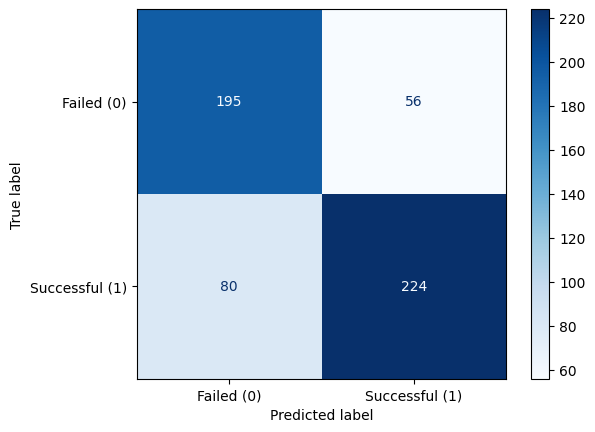

In [ ]:
# do a confusion matrix
cm = confusion_matrix(valid_df['success'], valid_df['llm_pred'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Failed (0)', 'Successful (1)'])
disp.plot(cmap='Blues')


In [11]:
# calculate precision, recall, f1-score
from sklearn.metrics import classification_report
report = classification_report(valid_df['success'], valid_df['llm_pred'], target_names=['Failed (0)', 'Successful (1)'])
print("\nClassification Report:\n", report)


Classification Report:
                 precision    recall  f1-score   support

    Failed (0)       0.71      0.78      0.74       251
Successful (1)       0.80      0.74      0.77       304

      accuracy                           0.75       555
     macro avg       0.75      0.76      0.75       555
  weighted avg       0.76      0.75      0.76       555



In [12]:
# calculate f1 score
from sklearn.metrics import f1_score
f1 = f1_score(valid_df['success'], valid_df['llm_pred'])
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.7671


In [13]:
# Save the results permanently
subset_df.to_csv("gemini_results_few_shot.csv", index=False)
print("Backup saved successfully!")

Backup saved successfully!


In [12]:
# Show the first 5 rows: Actual vs Prediction vs Reasoning
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
display(subset_df[['success', 'llm_pred', 'raw_response']].head(80))

,success,llm_pred,raw_response
0,1,1.0,"1\nThe campaign is highly likely to be successful. The extremely low funding goal of $184.80 USD makes it easily achievable, and the creator has a proven track record with a previously successful Kickstarter campaign, which builds significant trust and credibility."
1,0,0.0,"0\nThe campaign is likely to fail due to a critical lack of visual assets, with no static images or reward images, which significantly hinders engagement and trust despite a compelling story. This deficiency, combined with a high funding goal of $10,000 and a rushed launch (1 day between creation and launch), makes it challenging to attract sufficient backing."
2,1,1.0,"1\nThis campaign is highly likely to be successful. The creator has a proven track record with multiple successful pin Kickstarters, an established online presence, and an existing audience, which significantly de-risks the project. Furthermore, the very low funding goal of $500, combined with a product appealing to a massive fandom (Pokemon enamel pins) and excellent visual assets, makes it easily achievable."
3,0,0.0,"0\nThis campaign is highly likely to fail due to its extremely ambitious goal of $115,000 combined with a complete lack of visual media (no video, no images, no reward images), which is critical for a ""Photo"" category project. Furthermore, the very limited reward tiers and high lowest pledge level ($75) significantly restrict accessibility and potential backer engagement."
4,0,0.0,"0\nThis campaign is highly likely to fail due to a critical lack of visual content, including no video, static images, or reward images, which is essential for a ""fashion shoot"" project. Furthermore, the campaign offers only one vague reward tier with no description of what backers receive, failing to engage potential supporters effectively."
5,1,0.0,"0\nThe campaign is highly unlikely to succeed due to the complete absence of any visual media, including a video, static images, or reward images, which is critical for engagement and conveying project quality on Kickstarter. Despite a very low funding goal, the lack of visual presentation and a story that leans heavily on personal financial issues rather than a compelling project vision makes it difficult to attract backers."
6,0,0.0,"0\nThis campaign is likely to fail due to its extremely high funding goal of $78,500 combined with the critical absence of reward images, which are essential for backers to visualize what they are pledging for. Furthermore, the lack of pre-launch activity and any mentioned creator track record makes reaching such an ambitious target highly improbable."
7,1,1.0,"1\nThe campaign is likely to be successful due to its extremely low funding goal of $1000, which is easily achievable, especially for a community-backed project. Furthermore, the clear, tangible benefit of building local playgrounds for children, coupled with strong community collaboration and a history of past success, will likely rally sufficient local support to meet this modest target."
8,1,0.0,"0\nThe campaign is likely to fail due to a critical lack of visual assets, including no reward images and no static images beyond the main video, which significantly hinders backer engagement and trust. Furthermore, the absence of pre-launch activation and the extremely rushed launch (1 day between creation and launch) indicate poor strategic planning and marketing efforts, despite a compelling project idea and a relatively low funding goal."
9,0,0.0,"0\nThe campaign's $4,000,000 goal is astronomically high for a Kickstarter film, especially without an established creator reputation or pre-existing fanbase. This, coupled with a severe lack of visual media (zero static images) to convey the film's vision, makes success highly improbable."


In [14]:
# Select rows where llm_pred is not missing
valid_df = subset_df[subset_df['llm_pred'].notna()]

# Compare to ground truth
valid_df['is_correct'] = valid_df['llm_pred'] == valid_df['success']

# Calculate accuracy
accuracy = valid_df['is_correct'].mean()
# Number of correct predictions
num_correct = valid_df['is_correct'].sum()

# Number of incorrect predictions
num_incorrect = (~valid_df['is_correct']).sum()

print(f"Number of correct predictions: {num_correct}")
print(f"Number of incorrect predictions: {num_incorrect}")
print(f"Accuracy (excluding missing llm_pred): {accuracy:.2%}")

Number of correct predictions: 419
Number of incorrect predictions: 136
Accuracy (excluding missing llm_pred): 75.50%


In [22]:
# inspect incorrect predictions
incorrect_df = valid_df[~valid_df['is_correct']]
print(f"Number of incorrect predictions: {incorrect_df.shape[0]}")
print(incorrect_df[['success', 'llm_pred', 'raw_response']])

Number of incorrect predictions: 136
     success  llm_pred  \
5          1       0.0   
8          1       0.0   
15         1       0.0   
22         0       1.0   
27         0       1.0   
..       ...       ...   
537        1       0.0   
540        1       0.0   
541        1       0.0   
544        0       1.0   
551        0       1.0   

                                                                                                                                                                                                                                                                                                                                                                                                                                                      raw_response  
5                    0\nThe campaign is highly unlikely to succeed due to the complete absence of any visual media, including a video, static images, or reward images, which is critical for engagem

In [23]:
# inspect correctly identified successes
correct_success_df = valid_df[(valid_df['is_correct']) & (valid_df['success'] == 1)]
print(f"Number of correctly identified successes: {correct_success_df.shape[0]}")
print(correct_success_df[['success', 'llm_pred', 'raw_response']])

Number of correctly identified successes: 224
     success  llm_pred  \
0          1       1.0   
2          1       1.0   
7          1       1.0   
10         1       1.0   
11         1       1.0   
..       ...       ...   
539        1       1.0   
545        1       1.0   
549        1       1.0   
550        1       1.0   
554        1       1.0   

                                                                                                                                                                                                                                                                                                                                                                                                                             raw_response  
0                                                                                                                                                               1\nThe campaign is highly likely to be successful. Th

In [24]:
# inspect correctly identified failures
correct_failure_df = valid_df[(valid_df['is_correct']) & (valid_df['success'] == 0)]
print(f"Number of correctly identified failures: {correct_failure_df.shape[0]}")
print(correct_failure_df[['success', 'llm_pred', 'raw_response']])

Number of correctly identified failures: 195
     success  llm_pred  \
1          0       0.0   
3          0       0.0   
4          0       0.0   
6          0       0.0   
9          0       0.0   
..       ...       ...   
547        0       0.0   
548        0       0.0   
552        0       0.0   
553        0       0.0   
556        0       0.0   

                                                                                                                                                                                                                                                                                                                                                                                                         raw_response  
1                                          0\nThe campaign is likely to fail due to a critical lack of visual assets, with no static images or reward images, which significantly hinders engagement and trust despite a compelling story.

In [14]:
!pip install bertopic
!pip install sentence-transformers

  Using cached scikit_learn-1.8.0-cp312-cp312-win_amd64.whl.metadata (11 kB)
   ---------------------------------------- 0.0/670.6 kB ? eta -:--:--
   ---------------------------------------- 670.6/670.6 kB 5.2 MB/s  0:00:00
Using cached scikit_learn-1.8.0-cp312-cp312-win_amd64.whl (8.0 MB)

  Attempting uninstall: scikit-learn

    Found existing installation: scikit-learn 1.4.2

    Uninstalling scikit-learn-1.4.2:

   ---------------------------------------- 0/5 [scikit-learn]
      Successfully uninstalled scikit-learn-1.4.2
   ---------------------------------------- 0/5 [scikit-learn]
   ---------------------------------------- 0/5 [scikit-learn]
   ---------------------------------------- 0/5 [scikit-learn]
   ---------------------------------------- 0/5 [scikit-learn]
   ---------------------------------------- 0/5 [scikit-learn]
   ---------------------------------------- 0/5 [scikit-learn]
   ---------------------------------------- 0/5 [scikit-learn]
   ---------------------

  You can safely remove it manually.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
# extract the text explanations from raw_response
valid_df['llm_explanation'] = valid_df['raw_response'].str.replace(r'^[01]\s*\n?', '', regex=True)

# drop missing values in llm_explanation and convert to a list
docs = valid_df['llm_explanation'].dropna().tolist()

# check
print(docs[:5])

['The campaign is highly likely to be successful. The extremely low funding goal of $184.80 USD makes it easily achievable, and the creator has a proven track record with a previously successful Kickstarter campaign, which builds significant trust and credibility.', 'The campaign is likely to fail due to a critical lack of visual assets, with no static images or reward images, which significantly hinders engagement and trust despite a compelling story. This deficiency, combined with a high funding goal of $10,000 and a rushed launch (1 day between creation and launch), makes it challenging to attract sufficient backing.', 'This campaign is highly likely to be successful. The creator has a proven track record with multiple successful pin Kickstarters, an established online presence, and an existing audience, which significantly de-risks the project. Furthermore, the very low funding goal of $500, combined with a product appealing to a massive fandom (Pokemon enamel pins) and excellent v

In [16]:
import re
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

docs_cleaned = []

for doc in docs:
    # 1. Lowercase
    doc_lower = doc.lower()
    
    # 2. Remove punctuation and numbers
    doc_alpha = re.sub(r'[^a-z\s]', '', doc_lower)
    
    # 3. Remove stopwords
    words = doc_alpha.split()
    words_filtered = [w for w in words if w not in stop_words]
    
    # 4. Rejoin into cleaned document
    docs_cleaned.append(" ".join(words_filtered))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\00zso\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [17]:
# fit bertopic
from bertopic import BERTopic
topic_model = BERTopic(min_topic_size=20, language="english", calculate_probabilities=True)
topics, probs = topic_model.fit_transform(docs_cleaned)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [18]:
# inspect topics
topic_info = topic_model.get_topic_info()

In [19]:
# view top 5 topics
pd.set_option('display.max_colwidth', None)
#print(topic_info.head())

# show all
pd.set_option('display.max_colwidth', None)
print(topic_info)

   Topic  Count                               Name  \
0     -1      9  -1_game_campaign_credibility_goal   
1      0    286  0_campaign_successful_goal_likely   
2      1    260   1_images_visual_campaign_backers   

                                                                            Representation  \
0  [game, campaign, credibility, goal, backers, images, games, strong, funding, potential]   
1       [campaign, successful, goal, likely, funding, strong, highly, despite, clear, low]   
2          [images, visual, campaign, backers, reward, fail, critical, absence, due, lack]   

                                                                                                                                                                                                                                                                                                                                                                                                                      

In [20]:
valid_df['topic'] = topics

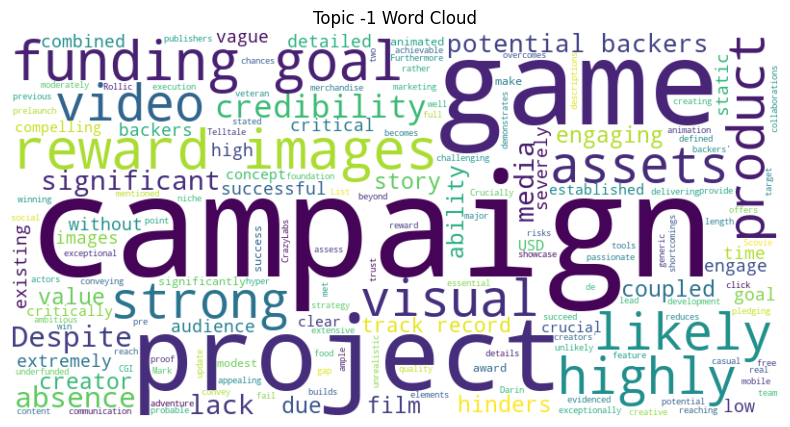

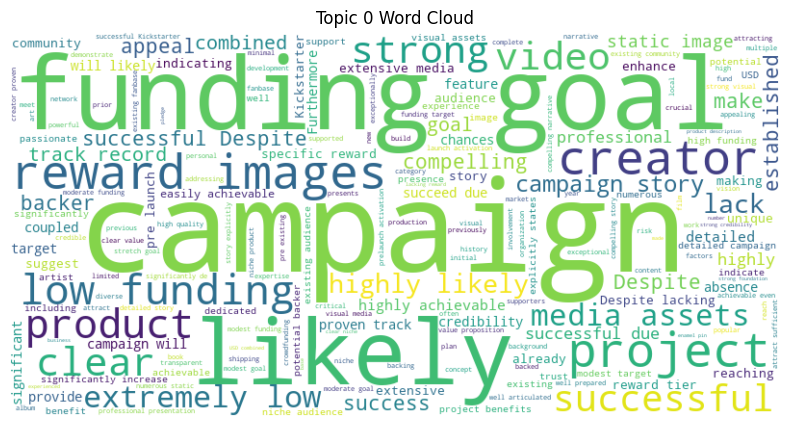

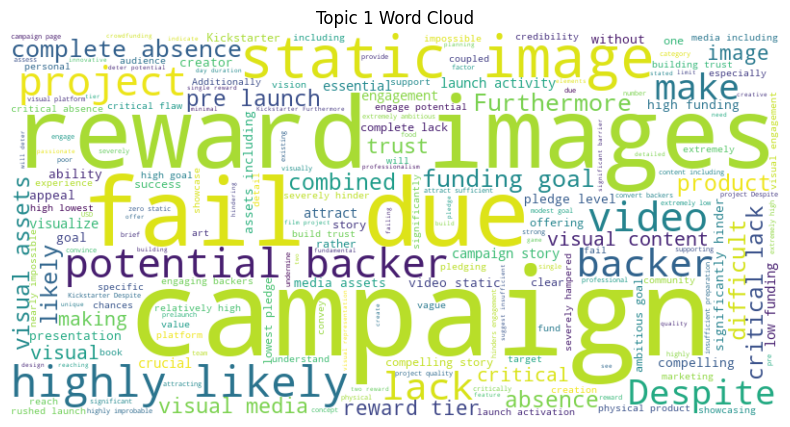

In [21]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

for t in topic_info['Topic'].unique():
    text = " ".join(valid_df[valid_df['topic'] == t]['llm_explanation'].tolist())
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10,5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f"Topic {t} Word Cloud")
    plt.show()

In [38]:
# Add a column for prediction correctness
valid_df['is_correct'] = valid_df['llm_pred'] == valid_df['success']

# Summarize counts per topic
topic_summary = valid_df.groupby(['topic', 'is_correct']).size().unstack(fill_value=0)
print(topic_summary)

is_correct  False  True 
topic                   
0              42    101
1              28    105


In [25]:
# visualize topics
topic_model.visualize_topics()

ValueError: zero-size array to reduction operation maximum which has no identity

In [19]:
# visualize topics
topic_model.visualize_topics()
topic_model.visualize_barchart()

ValueError: zero-size array to reduction operation maximum which has no identity